<a href="https://colab.research.google.com/github/Destinywaya9/ZERO/blob/main/QTET_Mathematical_Foundations_All_In_One.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QTET / QTL-Sphere — Mathematical Foundations Lab: All-in-One Colab Notebook

**Destiny Machwaya**  
**Copyright © 2015–2026 Destiny Machwaya. All rights reserved.**

This notebook combines the seven Mathematical Foundations Lab notebooks into one top-to-bottom Colab workflow.

## Mathematical lenses

1. **Folded Zero Mathematics** — finite inverse-pair closure, symbolic projection/return, folded-state visualization.
2. **P2 Combinatorics** — the exact Tensor P2 ordering inside the finite universe of orderings with the same coordinate multiset.
3. **Graph and Transition Mathematics** — coordinate graphs, event-lifted graphs, adjacency structure, recurrence topology.
4. **Linear Algebra Invariance** — basis changes, affine transforms, higher-dimensional embeddings, pseudoinverse recovery, conditioning.
5. **Topological Deformation Lab** — abstract path adjacency held fixed while geometric embeddings and smooth deformations change.
6. **Spectral and Recurrence Mathematics** — FFT, autocorrelation, recurrence period, exact-vs-counterfeit ordering under explicit scalar encoding.
7. **Mathematical Rosetta Stone** — tuple, matrix, graph, time-series, transition, embedding, and spectral views of one P2 traversal.

### Interpretation rule

Canonical QTET/QTL-Sphere objects are preserved where explicitly identified. Any encoding, embedding, distance, spectrum, deformation, matrix transform, graph lift, scalarization, or score introduced in this notebook is an **analysis / visualization construction**, not a replacement definition of the underlying framework.

**Recommended use:** open in Google Colab and choose **Runtime → Run all**.


## 0. Master Colab setup

In [ ]:
# Install the small dependency that may be absent in a fresh Colab runtime.
!pip -q install networkx

In [ ]:
# Shared numerical stack and canonical declarations used across modules.
import math
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import networkx as nx

from scipy import signal
from scipy.linalg import orth
from numpy.linalg import matrix_rank, pinv, cond
from IPython.display import display

RNG = np.random.default_rng(42)

# Canonical fixed Tensor P2 sequence.
P2_KERNEL = (
    (3, 3),
    (0, 0),
    (0, 1),
    (1, 2),
    (2, 1),
    (1, 0),
    (0, 0),
)
DELAY = 200

P2_ROLES = (
    'Bounded triadic entry',
    'Folded total-state reference after entry',
    'Differentiated traversal state',
    'Relational transition',
    'Inversion-paired transition',
    'Return-directed traversal',
    'Return to folded total-state reference',
)

assert P2_KERNEL == ((3,3),(0,0),(0,1),(1,2),(2,1),(1,0),(0,0))
assert DELAY == 200
print('Environment ready — canonical P2 and Delay verified.')

Environment ready — canonical P2 and Delay verified.


## Module 1 — Folded Zero Mathematics

Finite inverse-pair closure, symbolic projection/return, and folded-state visualization.

**Interpretation rule:** canonical QTET/QTL-Sphere objects are preserved where explicitly identified. Any encoding, embedding, distance, spectrum, deformation, matrix transform, graph lift, or score introduced here is an **analysis / visualization construction**, not a replacement definition of the underlying framework.

In [ ]:
RNG = np.random.default_rng(42)  # Reset for deterministic module-local experiments.

### 1. Canonical zero forms used in this notebook

The notebook preserves the disclosed finite form

\[
0_N = 0 + \sum_{n=1}^{N}(n+(-n)) = 0,
\]

and the folded/simultaneous notation

\[
0_Q = \{\ldots,-3,-2,-1,0,1,2,3,\ldots\}^{\parallel}.
\]

The symbol \(\parallel\) denotes simultaneous lawful coexistence in the disclosed formulation. The code below does **not** identify this notation with an ordinary convergent infinite series; it tests finite inverse-pair closure and symbolic projection/return relationships.

In [ ]:
def folded_zero_finite(N):
    N = int(N)
    if N < 0:
        raise ValueError('N must be >= 0')
    n = np.arange(1, N + 1, dtype=np.int64)
    pair_sums = n + (-n)
    return {
        'N': N,
        'represented_states': 2 * N + 1,
        'pair_count': N,
        'closure': int(pair_sums.sum()) if len(pair_sums) else 0,
        'all_pairs_close': bool(np.all(pair_sums == 0)),
    }

rows = [folded_zero_finite(N) for N in [0,1,2,10,100,1000,100000,1000000]]
zero_growth = pd.DataFrame(rows)
display(zero_growth)

,N,represented_states,pair_count,closure,all_pairs_close
0,0,1,0,0,True
1,1,3,1,0,True
2,2,5,2,0,True
3,10,21,10,0,True
4,100,201,100,0,True
5,1000,2001,1000,0,True
6,100000,200001,100000,0,True
7,1000000,2000001,1000000,0,True


### 2. Inverse-pair closure as the boundary expands

The state count grows as \(2N+1\), while every explicitly represented inverse pair still closes to ordinary scalar zero. This separates **size of the represented finite state set** from **pair-sum closure**.

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=zero_growth['N'].replace(0, np.nan),
    y=zero_growth['represented_states'],
    mode='lines+markers',
    name='Represented finite states'
))
fig.add_trace(go.Scatter(
    x=zero_growth['N'].replace(0, np.nan),
    y=zero_growth['closure'],
    mode='lines+markers',
    name='Pair-sum closure'
))
fig.update_layout(
    title='Finite boundary growth vs inverse-pair closure',
    xaxis_type='log',
    xaxis_title='Finite boundary N (log scale)',
    yaxis_title='Value',
    height=500
)
fig.show()

### 3. Symbolic projection and return

The disclosed relationships are represented symbolically:

\[
\pi_n(0_Q)=n,
\qquad
\rho(n)=0_Q,
\qquad
\rho(\pi_n(0_Q))=0_Q.
\]

`0_Q` is intentionally represented as a symbolic object rather than Python's scalar integer `0`.

In [ ]:
class FoldedTotalState:
    def __repr__(self):
        return '0_Q'

ZERO_Q = FoldedTotalState()

def pi_n(n):
    return int(n)

def rho(_n):
    return ZERO_Q

projection_examples = []
for n in [-100, -7, -1, 0, 1, 7, 100]:
    projected = pi_n(n)
    projection_examples.append({
        'n': n,
        'pi_n(0_Q)': projected,
        'rho(pi_n(0_Q))': repr(rho(projected))
    })
display(pd.DataFrame(projection_examples))

,n,pi_n(0_Q),rho(pi_n(0_Q))
0,-100,-100,0_Q
1,-7,-7,0_Q
2,-1,-1,0_Q
3,0,0,0_Q
4,1,1,0_Q
5,7,7,0_Q
6,100,100,0_Q


### 4. Folded inverse-pair visualization

This geometry is only a visualization. Opposite signed integers are placed as paired points connected through a central reference.

In [ ]:
def folded_geometry(N=12):
    N = int(N)
    n = np.arange(1, N+1)
    theta = 2*np.pi*(n-1)/max(N,1)
    r = n/max(N,1)
    xp, yp = r*np.cos(theta), r*np.sin(theta)
    xn, yn = -xp, -yp
    fig = go.Figure()
    for i in range(N):
        fig.add_trace(go.Scatter(
            x=[xp[i],0,xn[i]], y=[yp[i],0,yn[i]],
            mode='lines', line=dict(width=1),
            showlegend=False, hoverinfo='skip'
        ))
    fig.add_trace(go.Scatter(x=xp,y=yp,mode='markers+text',text=[f'+{v}' for v in n],name='+n'))
    fig.add_trace(go.Scatter(x=xn,y=yn,mode='markers+text',text=[f'-{v}' for v in n],name='-n'))
    fig.add_trace(go.Scatter(x=[0],y=[0],mode='markers+text',text=['0_Q ref'],marker=dict(size=22),name='folded reference'))
    fig.update_layout(title=f'Folded inverse-pair visualization | N={N}',xaxis=dict(visible=False,scaleanchor='y'),yaxis=dict(visible=False),height=650)
    fig.show()

folded_geometry(12)

### 5. Foundation check

Within the finite numerical construction tested here, inverse-pair closure is exact for every tested boundary. This is a computational check of the finite identity; it is not a numerical proof of the full interpretive content assigned to \(0_Q\).

## Module 2 — P2 Combinatorics

The exact Tensor P2 ordering inside the finite universe of orderings with the same coordinate multiset.

**Interpretation rule:** canonical QTET/QTL-Sphere objects are preserved where explicitly identified. Any encoding, embedding, distance, spectrum, deformation, matrix transform, graph lift, or score introduced here is an **analysis / visualization construction**, not a replacement definition of the underlying framework.

In [ ]:
RNG = np.random.default_rng(42)  # Reset for deterministic module-local experiments.

### 1. Combinatorial question

Tensor P2 contains seven traversal events but only six distinct coordinate values because \((0,0)\) occurs twice. Holding the coordinate multiset fixed, how many unique orderings exist, and how structurally unusual is the canonical ordering within that finite permutation universe?

In [ ]:
canonical = tuple(P2_KERNEL)
all_unique = sorted(set(itertools.permutations(canonical)))
print('Unique multiset permutations:', len(all_unique))
print('Expected from 7!/2! =', math.factorial(7)//math.factorial(2))
assert len(all_unique) == math.factorial(7)//math.factorial(2) == 2520

Unique multiset permutations: 2520
Expected from 7!/2! = 2520


In [ ]:
canonical_edges = list(zip(canonical[:-1], canonical[1:]))

def sequence_metrics(seq):
    seq = tuple(seq)
    positional_matches = sum(a == b for a,b in zip(seq, canonical))
    edges = list(zip(seq[:-1], seq[1:]))
    # Multiset-aware edge overlap: count each canonical edge at most as often as it occurs canonically.
    remaining = list(canonical_edges)
    overlap = 0
    for e in edges:
        if e in remaining:
            overlap += 1
            remaining.remove(e)
    return positional_matches, overlap

records=[]
for seq in all_unique:
    pm, eo = sequence_metrics(seq)
    records.append({'sequence': seq, 'positional_matches':pm, 'canonical_edge_overlap':eo, 'exact':seq==canonical})
perm_df = pd.DataFrame(records)
display(perm_df[['positional_matches','canonical_edge_overlap','exact']].describe())
print('Exact canonical sequence count:', int(perm_df['exact'].sum()))
print('Uniform unique-permutation probability:', 1/len(perm_df))

,positional_matches,canonical_edge_overlap
count,2520.000000,2520.000000
mean,1.285714,1.285714
std,1.075603,1.053225
min,0.000000,0.000000
25%,0.000000,1.000000
50%,1.000000,1.000000
75%,2.000000,2.000000
max,7.000000,6.000000


Exact canonical sequence count: 1
Uniform unique-permutation probability: 0.0003968253968253968


### 2. Distribution of near-P2 orderings

Two deliberately simple similarity measures are used:

- **positional matches**: same coordinate at the same traversal index;
- **canonical edge overlap**: same directed adjacent transition, counted with multiplicity.

These are analysis scores only.

In [ ]:
fig = go.Figure()
fig.add_trace(go.Histogram(x=perm_df['canonical_edge_overlap'], name='Edge overlap'))
fig.update_layout(title='Permutation universe by canonical-edge overlap',xaxis_title='Canonical directed edges preserved',yaxis_title='Number of unique orderings',bargap=0.1,height=450)
fig.show()

summary = perm_df.groupby(['canonical_edge_overlap','positional_matches']).size().reset_index(name='count')
display(summary.sort_values(['canonical_edge_overlap','positional_matches'],ascending=False).head(20))

,canonical_edge_overlap,positional_matches,count
32,6,7,1
31,5,5,1
30,5,2,4
29,5,1,5
28,5,0,4
27,4,5,3
26,4,4,5
25,4,3,7
24,4,2,9
23,4,1,11


### 3. One-swap neighborhood

A stricter local test asks what happens when exactly two traversal positions are swapped. Repeated \((0,0)\) events can make a nominal swap observationally identical, so duplicates are removed.

In [ ]:
swap_variants = set()
for i in range(len(canonical)):
    for j in range(i+1,len(canonical)):
        s=list(canonical)
        s[i],s[j]=s[j],s[i]
        swap_variants.add(tuple(s))

swap_rows=[]
for s in sorted(swap_variants):
    pm,eo=sequence_metrics(s)
    swap_rows.append({'sequence':s,'positional_matches':pm,'canonical_edge_overlap':eo,'exact':s==canonical})
swap_df=pd.DataFrame(swap_rows)
print('Distinct one-swap variants:',len(swap_df))
display(swap_df.sort_values(['canonical_edge_overlap','positional_matches'],ascending=False).head(15))

Distinct one-swap variants: 21


,sequence,positional_matches,canonical_edge_overlap,exact
12,"((3, 3), (0, 0), (0, 1), (1, 2), (2, 1), (1, 0...",7,6,True
3,"((1, 0), (0, 0), (0, 1), (1, 2), (2, 1), (3, 3...",5,5,False
0,"((0, 0), (0, 0), (0, 1), (1, 2), (2, 1), (1, 0...",5,4,False
1,"((0, 0), (3, 3), (0, 1), (1, 2), (2, 1), (1, 0...",5,4,False
11,"((3, 3), (0, 0), (0, 1), (1, 2), (2, 1), (0, 0...",5,4,False
2,"((0, 1), (0, 0), (3, 3), (1, 2), (2, 1), (1, 0...",5,3,False
4,"((1, 2), (0, 0), (0, 1), (3, 3), (2, 1), (1, 0...",5,3,False
5,"((2, 1), (0, 0), (0, 1), (1, 2), (3, 3), (1, 0...",5,3,False
6,"((3, 3), (0, 0), (0, 0), (1, 2), (2, 1), (1, 0...",5,3,False
7,"((3, 3), (0, 0), (0, 1), (0, 0), (2, 1), (1, 0...",5,3,False


### 4. Interpretation boundary

This notebook establishes finite combinatorial facts about the declared seven-event coordinate multiset. Rarity under a chosen permutation ensemble is not, by itself, a physical probability or evidence that nature samples those orderings uniformly.

## Module 3 — Graph and Transition Mathematics

Coordinate graphs, event-lifted graphs, adjacency structure, and recurrence topology.

**Interpretation rule:** canonical QTET/QTL-Sphere objects are preserved where explicitly identified. Any encoding, embedding, distance, spectrum, deformation, matrix transform, graph lift, or score introduced here is an **analysis / visualization construction**, not a replacement definition of the underlying framework.

In [ ]:
RNG = np.random.default_rng(42)  # Reset for deterministic module-local experiments.

### 1. Two graph representations

The same traversal can be represented in at least two useful ways:

1. a **coordinate graph**, where repeated coordinates collapse to one graph node;
2. a **temporally lifted event graph**, where traversal events remain distinct even if their coordinates coincide.

The lifted labels are observer/index labels only. They do not create a second mathematical \((0,0)\) coordinate.

In [ ]:
def coordinate_graph(include_delay=False, recurrence=False):
    seq=[f'{x},{y}' for x,y in P2_KERNEL]
    if include_delay:
        seq.append(f'Delay({DELAY})')
    G=nx.DiGraph()
    for a,b in zip(seq[:-1],seq[1:]):
        if G.has_edge(a,b): G[a][b]['count'] += 1
        else: G.add_edge(a,b,count=1)
    if recurrence:
        G.add_edge(seq[-1],seq[0],count=G.get_edge_data(seq[-1],seq[0],{}).get('count',0)+1)
    return G

G_coord=coordinate_graph(include_delay=True,recurrence=True)
print('Coordinate nodes:',G_coord.number_of_nodes())
print('Coordinate edges:',G_coord.number_of_edges())
print('Successors of 0,0:',list(G_coord.successors('0,0')))

Coordinate nodes: 7
Coordinate edges: 8
Successors of 0,0: ['0,1', 'Delay(200)']


In [ ]:
def event_graph(include_delay=True, recurrence=True):
    events=[f'e{i}:{x},{y}' for i,(x,y) in enumerate(P2_KERNEL)]
    if include_delay:
        events.append(f'e7:Delay({DELAY})')
    G=nx.DiGraph()
    G.add_nodes_from(events)
    G.add_edges_from(zip(events[:-1],events[1:]))
    if recurrence:
        G.add_edge(events[-1],events[0])
    return G

G_event=event_graph()
print('Event nodes:',G_event.number_of_nodes())
print('Event edges:',G_event.number_of_edges())
print('Strongly connected:',nx.is_strongly_connected(G_event))
print('Simple directed cycle length:',len(nx.find_cycle(G_event)))

Event nodes: 8
Event edges: 8
Strongly connected: True
Simple directed cycle length: 8


### 2. Visual comparison

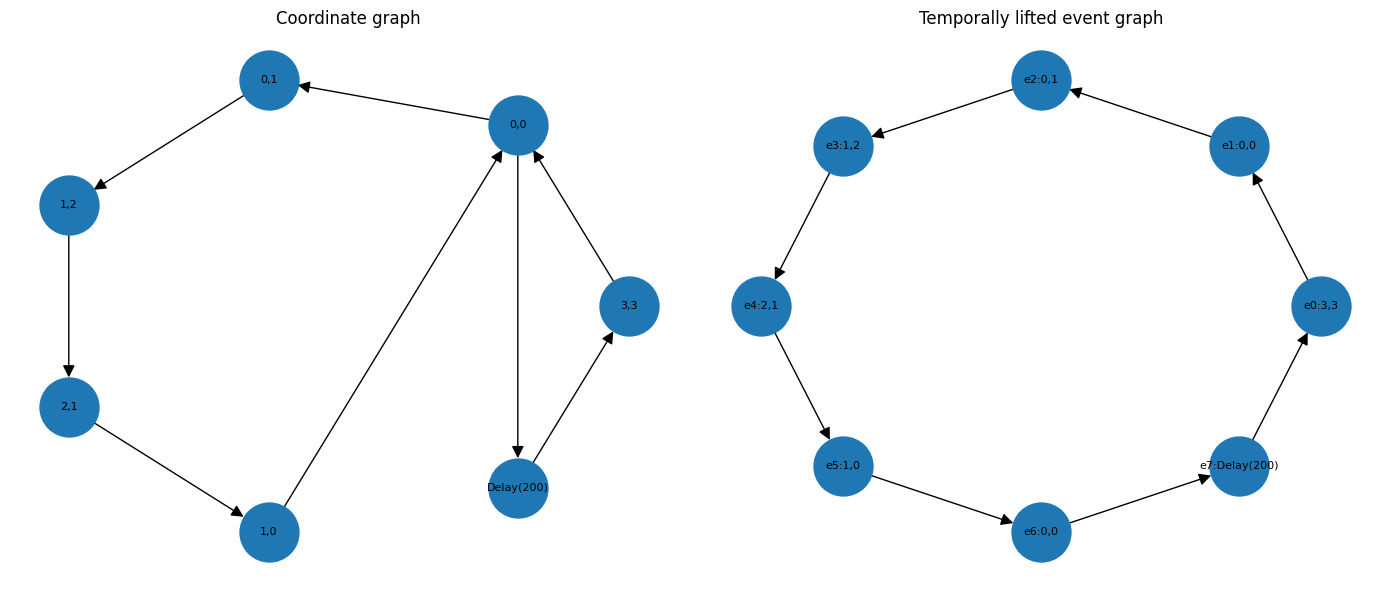

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(14,6))
for ax,G,title in [(axes[0],G_coord,'Coordinate graph'),(axes[1],G_event,'Temporally lifted event graph')]:
    pos=nx.circular_layout(G)
    nx.draw_networkx(G,pos,ax=ax,node_size=1800,font_size=8,arrows=True,arrowsize=18)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 3. Adjacency matrices and graph invariants

In [ ]:
def graph_summary(G,name):
    A=nx.to_numpy_array(G,dtype=float)
    return {
        'graph':name,
        'nodes':G.number_of_nodes(),
        'edges':G.number_of_edges(),
        'strong_components':nx.number_strongly_connected_components(G),
        'weak_components':nx.number_weakly_connected_components(G),
        'rank_adjacency':int(matrix_rank(A)),
        'trace_adjacency':float(np.trace(A))
    }

graph_summaries=pd.DataFrame([
    graph_summary(G_coord,'coordinate recurrence graph'),
    graph_summary(G_event,'event recurrence graph')
])
display(graph_summaries)

coord_nodes=list(G_coord.nodes())
A_coord=nx.to_pandas_adjacency(G_coord,nodelist=coord_nodes,dtype=int)
display(A_coord)

,graph,nodes,edges,strong_components,weak_components,rank_adjacency,trace_adjacency
0,coordinate recurrence graph,7,8,1,1,6,0.0
1,event recurrence graph,8,8,1,1,8,0.0


,"3,3","0,0","0,1","1,2","2,1","1,0",Delay(200)
"3,3",0,1,0,0,0,0,0
"0,0",0,0,1,0,0,0,1
"0,1",0,0,0,1,0,0,0
"1,2",0,0,0,0,1,0,0
"2,1",0,0,0,0,0,1,0
"1,0",0,1,0,0,0,0,0
Delay(200),1,0,0,0,0,0,0


### 4. Why the repeated coordinate matters

Collapsing the two \((0,0)\) traversal events into one graph node produces a node with multiple outgoing transitions. Lifting by temporal event index restores deterministic next-event structure. This is an information-representation result, not a claim that the coordinate itself has become two different states.

## Module 4 — Linear Algebra Invariance

Basis changes, affine transforms, higher-dimensional embeddings, pseudoinverse recovery, and numerical conditioning.

**Interpretation rule:** canonical QTET/QTL-Sphere objects are preserved where explicitly identified. Any encoding, embedding, distance, spectrum, deformation, matrix transform, graph lift, or score introduced here is an **analysis / visualization construction**, not a replacement definition of the underlying framework.

In [ ]:
RNG = np.random.default_rng(42)  # Reset for deterministic module-local experiments.

### 1. P2 as a coordinate matrix

For representation analysis only, write the seven coordinate observations as

\[
X = \begin{pmatrix}
3&3\\0&0\\0&1\\1&2\\2&1\\1&0\\0&0
\end{pmatrix}.
\]

We then transform the **representation** while retaining the traversal row order.

In [ ]:
X=np.array(P2_KERNEL,dtype=float)
display(pd.DataFrame(X,columns=['x','y']))
print('Matrix rank:',matrix_rank(X))

,x,y
0,3.0,3.0
1,0.0,0.0
2,0.0,1.0
3,1.0,2.0
4,2.0,1.0
5,1.0,0.0
6,0.0,0.0


Matrix rank: 2


### 2. Invertible 2D basis changes

For synthetic invertible matrices \(A\) and offsets \(b\), use \(Y=XA+b\), then recover \(X\) with the inverse transform.

In [ ]:
def random_invertible_2d(rng=RNG):
    while True:
        A=rng.normal(size=(2,2))
        if abs(np.linalg.det(A))>0.2:
            return A

def affine_roundtrip_trials(trials=1000):
    rows=[]
    for k in range(trials):
        A=random_invertible_2d()
        b=RNG.normal(size=2)
        Y=X@A+b
        Xrec=(Y-b)@np.linalg.inv(A)
        err=float(np.max(np.abs(Xrec-X)))
        rows.append({'trial':k,'condition_number':float(cond(A)),'max_recovery_error':err})
    return pd.DataFrame(rows)

affine_results=affine_roundtrip_trials(1000)
display(affine_results.describe())

,trial,condition_number,max_recovery_error
count,1000.000000,1000.000000,1.000000e+03
mean,499.500000,4.786556,7.882454e-16
std,288.819436,4.571782,8.542377e-16
min,0.000000,1.040158,1.572304e-17
25%,249.750000,2.089609,4.440892e-16
50%,499.500000,3.210290,4.440892e-16
75%,749.250000,5.526457,8.881784e-16
max,999.000000,35.808772,9.325873e-15


### 3. Higher-dimensional linear embeddings

A full-row-rank 2-to-D map \(B\) creates \(Y=XB\). The original 2D representation can be recovered with a Moore-Penrose pseudoinverse when the embedding retains rank 2.

In [ ]:
def higher_dimensional_trials(dimensions=(3,4,5,10,20,50,100), trials_each=100):
    rows=[]
    for D in dimensions:
        for k in range(trials_each):
            while True:
                B=RNG.normal(size=(2,D))
                if matrix_rank(B)==2:
                    break
            Y=X@B
            Xrec=Y@pinv(B)
            rows.append({'D':D,'trial':k,'rank_B':matrix_rank(B),'max_recovery_error':float(np.max(np.abs(Xrec-X)))})
    return pd.DataFrame(rows)

embed_results=higher_dimensional_trials()
display(embed_results.groupby('D')['max_recovery_error'].agg(['mean','max']))

,mean,max
D,,
3,1.799672e-15,8.881784e-15
4,1.479927e-15,5.329071e-15
5,1.378984e-15,4.440892e-15
10,1.280392e-15,3.996803e-15
20,1.409983e-15,3.552714e-15
50,1.383338e-15,3.552714e-15
100,1.623146e-15,4.440892e-15


### 4. Numerical conditioning stress test

Exact invertibility is distinct from numerical stability. This cell deliberately creates increasingly ill-conditioned transformations and measures floating-point recovery error.

In [ ]:
angles=np.linspace(0,2*np.pi,200,endpoint=False)
rows=[]
for exponent in range(0,15):
    s=10.0**(-exponent)
    A=np.array([[1.0,1.0],[0.0,s]])
    Y=X@A
    Xrec=Y@np.linalg.inv(A)
    rows.append({'small_singular_scale':s,'condition_number':cond(A),'max_error':np.max(np.abs(Xrec-X))})
conditioning=pd.DataFrame(rows)
display(conditioning)

fig=go.Figure(go.Scatter(x=conditioning['condition_number'],y=conditioning['max_error'],mode='lines+markers'))
fig.update_layout(title='Numerical recovery error vs transformation conditioning',xaxis_type='log',yaxis_type='log',xaxis_title='Condition number',yaxis_title='Max absolute round-trip error',height=450)
fig.show()

,small_singular_scale,condition_number,max_error
0,1.000000e+00,2.618034e+00,0.000000e+00
1,1.000000e-01,2.005012e+01,1.776357e-15
2,1.000000e-02,2.000050e+02,2.131628e-14
3,1.000000e-03,2.000001e+03,1.136868e-13
4,1.000000e-04,2.000000e+04,2.110312e-12
5,1.000000e-05,2.000000e+05,3.420508e-11
6,1.000000e-06,2.000000e+06,1.397780e-10
7,1.000000e-07,2.000000e+07,1.636579e-09
8,1.000000e-08,2.000000e+08,1.823241e-08
9,1.000000e-09,2.000000e+09,8.274037e-08


### 5. Interpretation boundary

The tests show representation recoverability under explicitly known invertible or rank-preserving linear maps. They do not imply that arbitrary physical observations come with a known inverse map.

## Module 5 — Topological Deformation Lab

Abstract path adjacency held fixed while geometric embeddings and continuous deformations change.

**Interpretation rule:** canonical QTET/QTL-Sphere objects are preserved where explicitly identified. Any encoding, embedding, distance, spectrum, deformation, matrix transform, graph lift, or score introduced here is an **analysis / visualization construction**, not a replacement definition of the underlying framework.

In [ ]:
RNG = np.random.default_rng(42)  # Reset for deterministic module-local experiments.

### 1. Abstract path vs geometric drawing

This notebook separates an abstract event-adjacency path from the geometry used to draw it. The seven event indices form an abstract path graph \(P_7\). Continuous-looking drawing deformations can radically change shape without changing that declared adjacency.

In [ ]:
G_path=nx.path_graph(len(P2_KERNEL),create_using=nx.DiGraph)
G_cycle=G_path.copy()
G_cycle.add_edge(len(P2_KERNEL)-1,0)

def abstract_summary(G,name):
    und=G.to_undirected()
    V=G.number_of_nodes(); E=G.number_of_edges()
    return {'representation':name,'V':V,'E':E,'components':nx.number_connected_components(und),'cycle_rank':E-V+nx.number_connected_components(und),'Euler_V_minus_E':V-E}

display(pd.DataFrame([abstract_summary(G_path,'single traversal path'),abstract_summary(G_cycle,'recurrence-closed cycle')]))

,representation,V,E,components,cycle_rank,Euler_V_minus_E
0,single traversal path,7,6,1,0,1
1,recurrence-closed cycle,7,7,1,1,0


### 2. Multiple geometric embeddings of the same abstract path

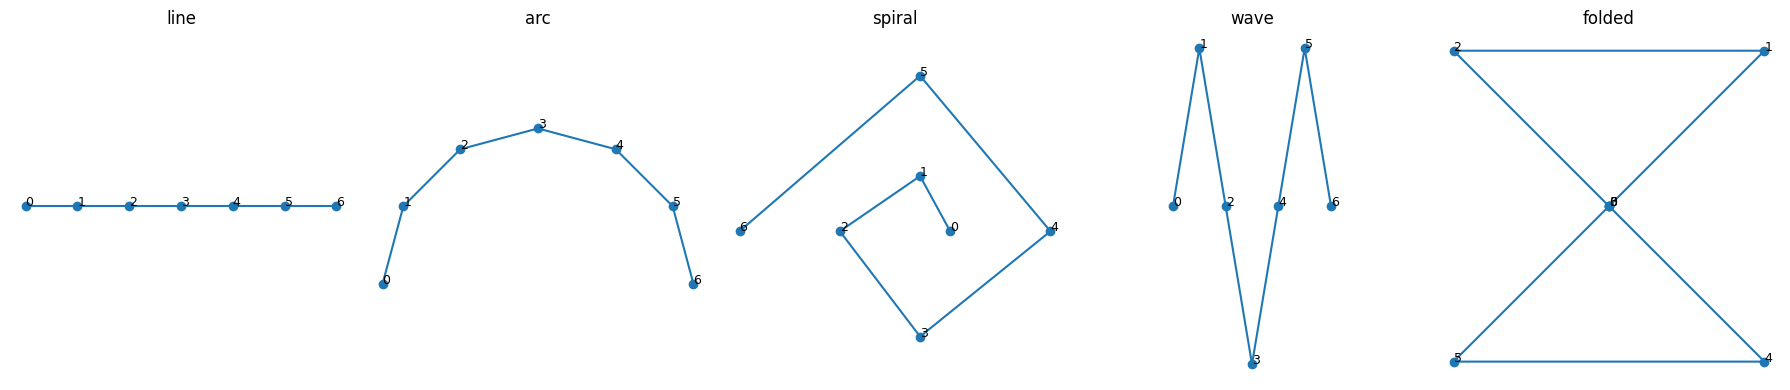

In [ ]:
def embeddings_for_path(n=7):
    t=np.linspace(0,1,n)
    return {
        'line':np.column_stack([t,np.zeros(n)]),
        'arc':np.column_stack([np.cos(np.pi*(1-t)),np.sin(np.pi*(1-t))]),
        'spiral':np.column_stack([(0.2+t)*np.cos(3*np.pi*t),(0.2+t)*np.sin(3*np.pi*t)]),
        'wave':np.column_stack([t,np.sin(3*np.pi*t)]),
        'folded':np.column_stack([np.sin(4*np.pi*t),np.sin(2*np.pi*t)])
    }

emb=embeddings_for_path()
fig,axes=plt.subplots(1,len(emb),figsize=(18,4))
for ax,(name,pts) in zip(axes,emb.items()):
    ax.plot(pts[:,0],pts[:,1],'-o')
    for i,(x,y) in enumerate(pts): ax.text(x,y,str(i),fontsize=9)
    ax.set_title(name); ax.axis('equal'); ax.axis('off')
plt.tight_layout(); plt.show()

### 3. Adjacency-preservation check

In [ ]:
declared_edges=set(G_path.edges())
rows=[]
for name,pts in emb.items():
    # The drawing changes coordinates only; edge list remains declared by event order.
    rendered_edges=set(zip(range(len(pts)-1),range(1,len(pts))))
    rows.append({'embedding':name,'same_declared_edges':rendered_edges==declared_edges,'vertices':len(pts),'edges':len(rendered_edges)})
display(pd.DataFrame(rows))

,embedding,same_declared_edges,vertices,edges
0,line,True,7,6
1,arc,True,7,6
2,spiral,True,7,6
3,wave,True,7,6
4,folded,True,7,6


### 4. Random smooth deformation family

The next experiment changes point positions continuously using a parameter \(\lambda\) while retaining event adjacency.

In [ ]:
base=emb['line']
target=emb['folded']
lambdas=np.linspace(0,1,11)
rows=[]
for lam in lambdas:
    pts=(1-lam)*base+lam*target
    edge_lengths=np.linalg.norm(np.diff(pts,axis=0),axis=1)
    rows.append({'lambda':lam,'total_geometric_length':edge_lengths.sum(),'min_edge_length':edge_lengths.min(),'abstract_edges_preserved':True})
deform_df=pd.DataFrame(rows)
display(deform_df)
fig=go.Figure(go.Scatter(x=deform_df['lambda'],y=deform_df['total_geometric_length'],mode='lines+markers'))
fig.update_layout(title='Geometry changes while declared path adjacency is held fixed',xaxis_title='Deformation parameter lambda',yaxis_title='Total rendered path length',height=420)
fig.show()

,lambda,total_geometric_length,min_edge_length,abstract_edges_preserved
0,0.0,1.000000,0.166667,True
1,0.1,1.054226,0.023205,True
2,0.2,1.834505,0.213077,True
3,0.3,2.635576,0.402949,True
4,0.4,3.445843,0.565050,True
5,0.5,4.260901,0.673879,True
6,0.6,5.078756,0.783407,True
7,0.7,5.898378,0.893377,True
8,0.8,6.719186,1.003643,True
9,0.9,7.540829,1.114118,True


### 5. Interpretation boundary

This notebook demonstrates invariance of an explicitly held abstract path graph under changes to its drawing. It is not a proof of a broader physical topological equivalence theorem.

## Module 6 — Spectral and Recurrence Mathematics

FFT, autocorrelation, recurrence period, and exact-vs-counterfeit ordering under an explicit scalar analysis encoding.

**Interpretation rule:** canonical QTET/QTL-Sphere objects are preserved where explicitly identified. Any encoding, embedding, distance, spectrum, deformation, matrix transform, graph lift, or score introduced here is an **analysis / visualization construction**, not a replacement definition of the underlying framework.

In [ ]:
RNG = np.random.default_rng(42)  # Reset for deterministic module-local experiments.

### 1. Analysis encoding

Spectral methods require a scalar signal. The mapping below assigns each coordinate a numerical analysis code. This code is **not** a canonical value of the P2 states; it exists only so FFT, autocorrelation, and spectrogram tools can analyze recurrence.

In [ ]:
unique_states=[]
for s in P2_KERNEL:
    if s not in unique_states: unique_states.append(s)
STATE_CODE={s:i+1 for i,s in enumerate(unique_states)}
STATE_CODE[(0,0)] = 2  # repeated coordinate intentionally receives the same coordinate code
print(STATE_CODE)

def cycle_signal(sequence=P2_KERNEL,delay_samples=DELAY):
    state_part=np.array([STATE_CODE[s] for s in sequence],dtype=float)
    delay_part=np.zeros(int(delay_samples),dtype=float)
    return np.concatenate([state_part,delay_part])

base_cycle=cycle_signal()
print('Samples per recurrence cycle:',len(base_cycle))
assert len(base_cycle)==len(P2_KERNEL)+DELAY

{(3, 3): 1, (0, 0): 2, (0, 1): 3, (1, 2): 4, (2, 1): 5, (1, 0): 6}
Samples per recurrence cycle: 207


### 2. Long recurrence trace and FFT

In [ ]:
cycles=300
trace=np.tile(base_cycle,cycles)
centered=trace-trace.mean()
fft=np.fft.rfft(centered)
freq=np.fft.rfftfreq(len(centered),d=1.0)
power=np.abs(fft)**2

idx=np.argsort(power[1:])[-10:]+1
dominant=pd.DataFrame({'frequency':freq[idx],'power':power[idx]}).sort_values('power',ascending=False)
display(dominant)

fig=go.Figure(go.Scatter(x=freq[1:],y=power[1:],mode='lines'))
fig.update_layout(title='FFT power spectrum of encoded recurring P2 + Delay(200)',xaxis_title='Cycles per sample',yaxis_title='Power',xaxis_range=[0,0.08],height=450)
fig.show()

,frequency,power
9,0.004831,4.749635e+07
8,0.009662,4.715686e+07
7,0.014493,4.659585e+07
6,0.019324,4.582042e+07
5,0.024155,4.484034e+07
4,0.028986,4.366787e+07
3,0.033816,4.231754e+07
2,0.038647,4.080586e+07
1,0.043478,3.915109e+07
0,0.048309,3.737286e+07


### 3. Autocorrelation recurrence signature

In [ ]:
def normalized_autocorr(x,max_lag=1000):
    x=np.asarray(x,float); x=x-x.mean()
    full=signal.correlate(x,x,mode='full',method='fft')
    ac=full[len(x)-1:len(x)+max_lag]
    return ac/ac[0]

ac=normalized_autocorr(trace,1000)
expected_period=len(base_cycle)
print('Expected encoded recurrence period:',expected_period)
print('Autocorrelation at one period:',ac[expected_period])

fig=go.Figure(go.Scatter(x=np.arange(len(ac)),y=ac,mode='lines'))
fig.add_vline(x=expected_period,line_dash='dash')
fig.update_layout(title='Autocorrelation of encoded recurrence trace',xaxis_title='Lag (samples)',yaxis_title='Normalized autocorrelation',height=450)
fig.show()

Expected encoded recurrence period: 207
Autocorrelation at one period: 0.9966666666666665


### 4. Exact P2 vs same-multiset counterfeit

A counterfeit sequence swaps two nonidentical traversal positions but retains the same coordinate multiset. The comparison asks whether ordering changes the encoded spectrum.

In [ ]:
counterfeit=list(P2_KERNEL)
counterfeit[2],counterfeit[4]=counterfeit[4],counterfeit[2]
counterfeit=tuple(counterfeit)
assert sorted(counterfeit)==sorted(P2_KERNEL)
assert counterfeit!=P2_KERNEL

trace_true=np.tile(cycle_signal(P2_KERNEL),300)
trace_fake=np.tile(cycle_signal(counterfeit),300)
P_true=np.abs(np.fft.rfft(trace_true-trace_true.mean()))**2
P_fake=np.abs(np.fft.rfft(trace_fake-trace_fake.mean()))**2
relative_spectral_difference=np.linalg.norm(P_true-P_fake)/max(np.linalg.norm(P_true),1e-12)
print('Relative spectral difference:',relative_spectral_difference)

f=np.fft.rfftfreq(len(trace_true),d=1.0)
fig=go.Figure()
fig.add_trace(go.Scatter(x=f,y=P_true,mode='lines',name='Exact P2'))
fig.add_trace(go.Scatter(x=f,y=P_fake,mode='lines',name='Counterfeit same-multiset order'))
fig.update_layout(title='Spectral effect of traversal ordering under one analysis encoding',xaxis_range=[0,0.08],xaxis_title='Cycles per sample',yaxis_title='Power',height=450)
fig.show()

Relative spectral difference: 0.0910820665673077


### 5. Interpretation boundary

Spectral fingerprints depend on the chosen scalar encoding and sampling convention. A difference here shows that order can affect an explicitly constructed signal representation; it does not assign a unique physical spectrum to Tensor P2.

## Module 7 — Mathematical Rosetta Stone

A cross-representation hub for tuple, matrix, graph, time-series, transition, embedding, and spectral views of one P2 traversal.

**Interpretation rule:** canonical QTET/QTL-Sphere objects are preserved where explicitly identified. Any encoding, embedding, distance, spectrum, deformation, matrix transform, graph lift, or score introduced here is an **analysis / visualization construction**, not a replacement definition of the underlying framework.

In [ ]:
RNG = np.random.default_rng(42)  # Reset for deterministic module-local experiments.

### 1. One declared traversal, many mathematical representations

This notebook is the cross-representation hub. The same seven P2 traversal events are shown as:

- ordered tuple;
- coordinate matrix;
- event-lifted directed graph;
- event-index time series;
- transition matrix;
- synthetic 3D embedding;
- scalar spectral representation.

Changing the mathematical lens does not change the declared traversal.

In [ ]:
P2_MATRIX=np.array(P2_KERNEL,dtype=float)
EVENT_LABELS=[f'e{i}' for i in range(len(P2_KERNEL))]
EVENT_GRAPH=nx.DiGraph()
EVENT_GRAPH.add_nodes_from(range(len(P2_KERNEL)))
EVENT_GRAPH.add_edges_from(zip(range(len(P2_KERNEL)-1),range(1,len(P2_KERNEL))))

# Scalar analysis code used only for time/spectral panels.
coord_codes={}
next_code=1
for s in P2_KERNEL:
    if s not in coord_codes:
        coord_codes[s]=next_code; next_code+=1
P2_CODES=np.array([coord_codes[s] for s in P2_KERNEL],dtype=float)

print('Ordered tuple:')
print(P2_KERNEL)
print('\nCoordinate matrix:')
display(pd.DataFrame(P2_MATRIX,columns=['x','y'],index=EVENT_LABELS))

Ordered tuple:
((3, 3), (0, 0), (0, 1), (1, 2), (2, 1), (1, 0), (0, 0))

Coordinate matrix:


,x,y
e0,3.0,3.0
e1,0.0,0.0
e2,0.0,1.0
e3,1.0,2.0
e4,2.0,1.0
e5,1.0,0.0
e6,0.0,0.0


### 2. Rosetta dashboard

Call `display_rosetta(step)` with any step from 0 to 6. The selected traversal event is highlighted across all panels.

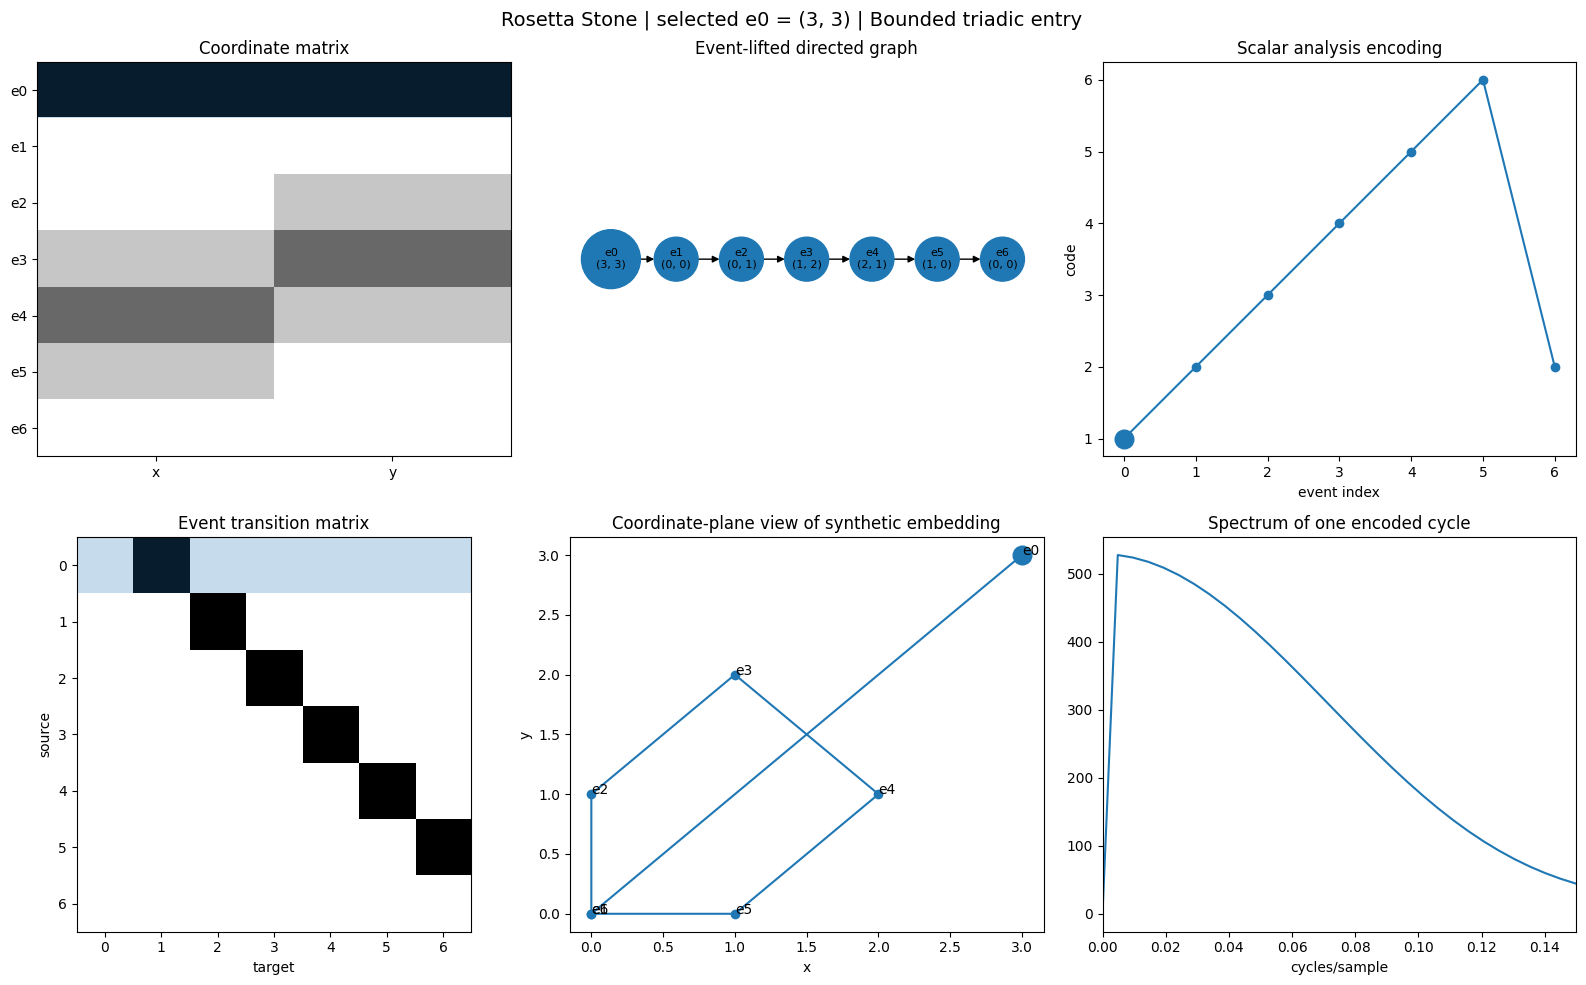

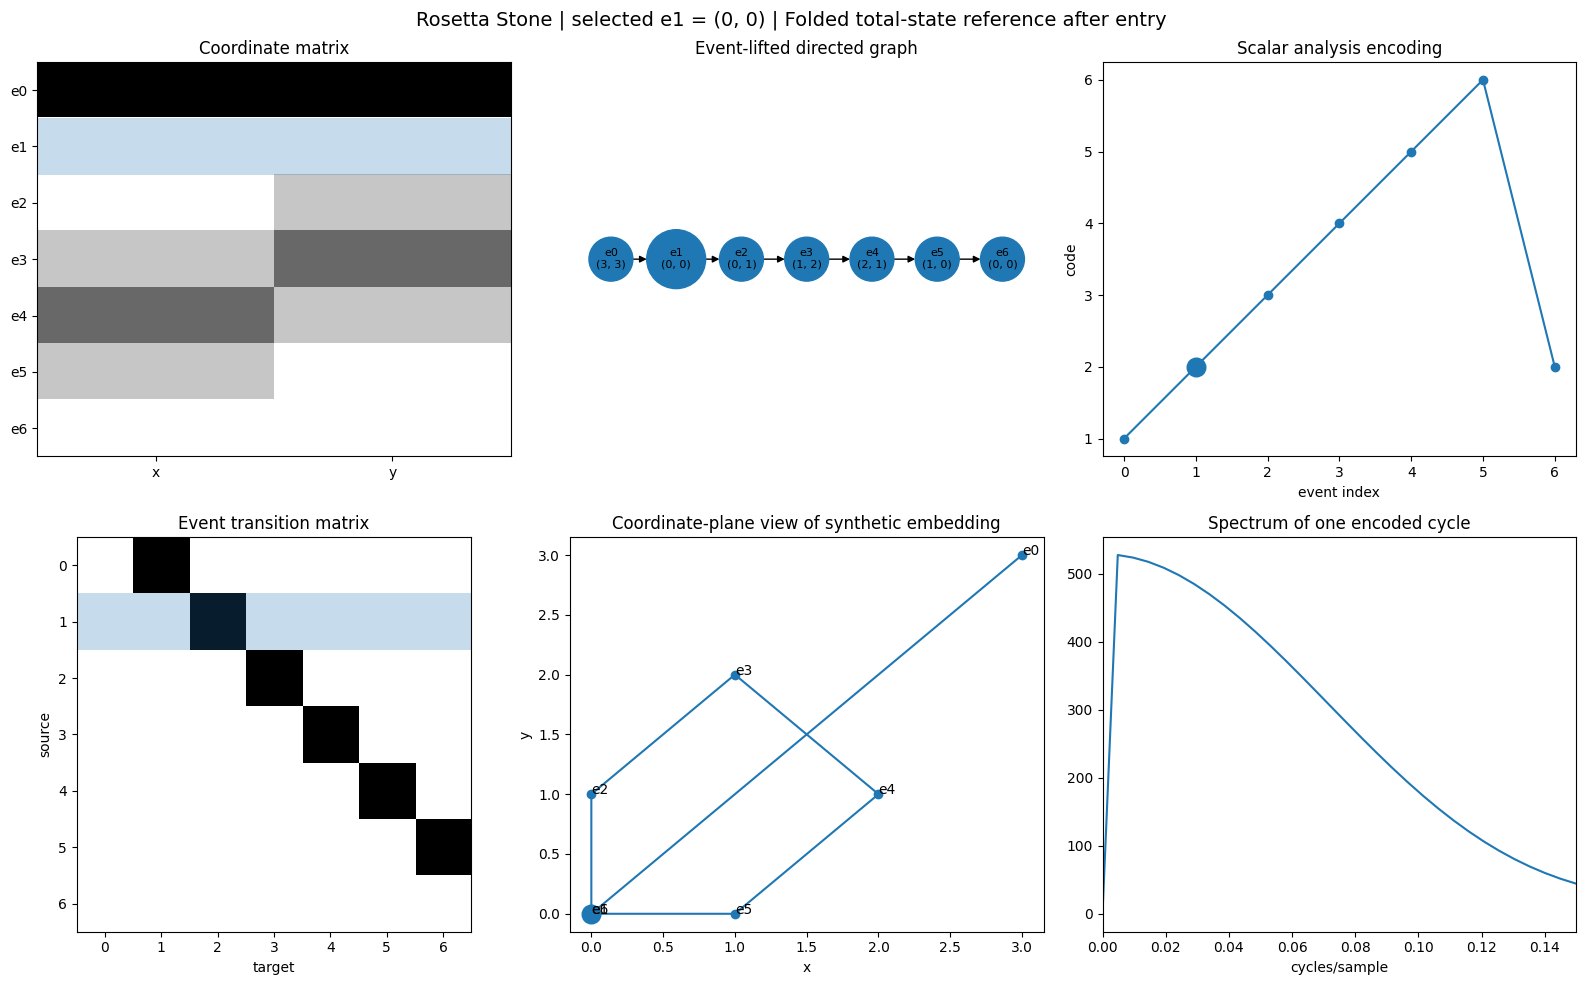

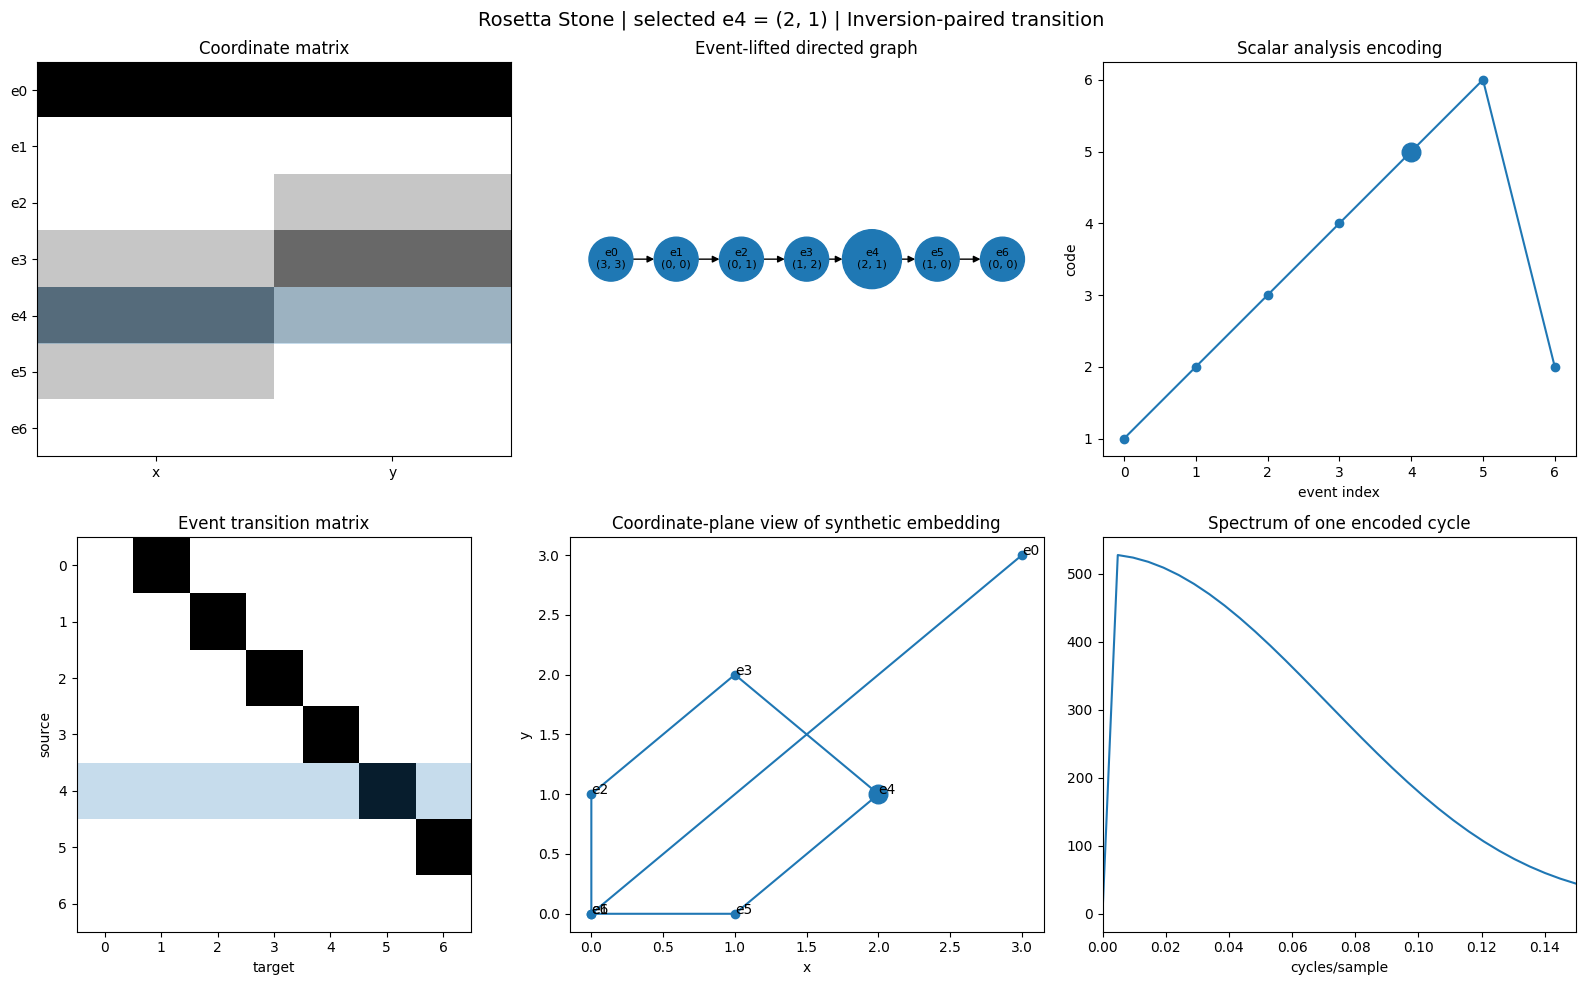

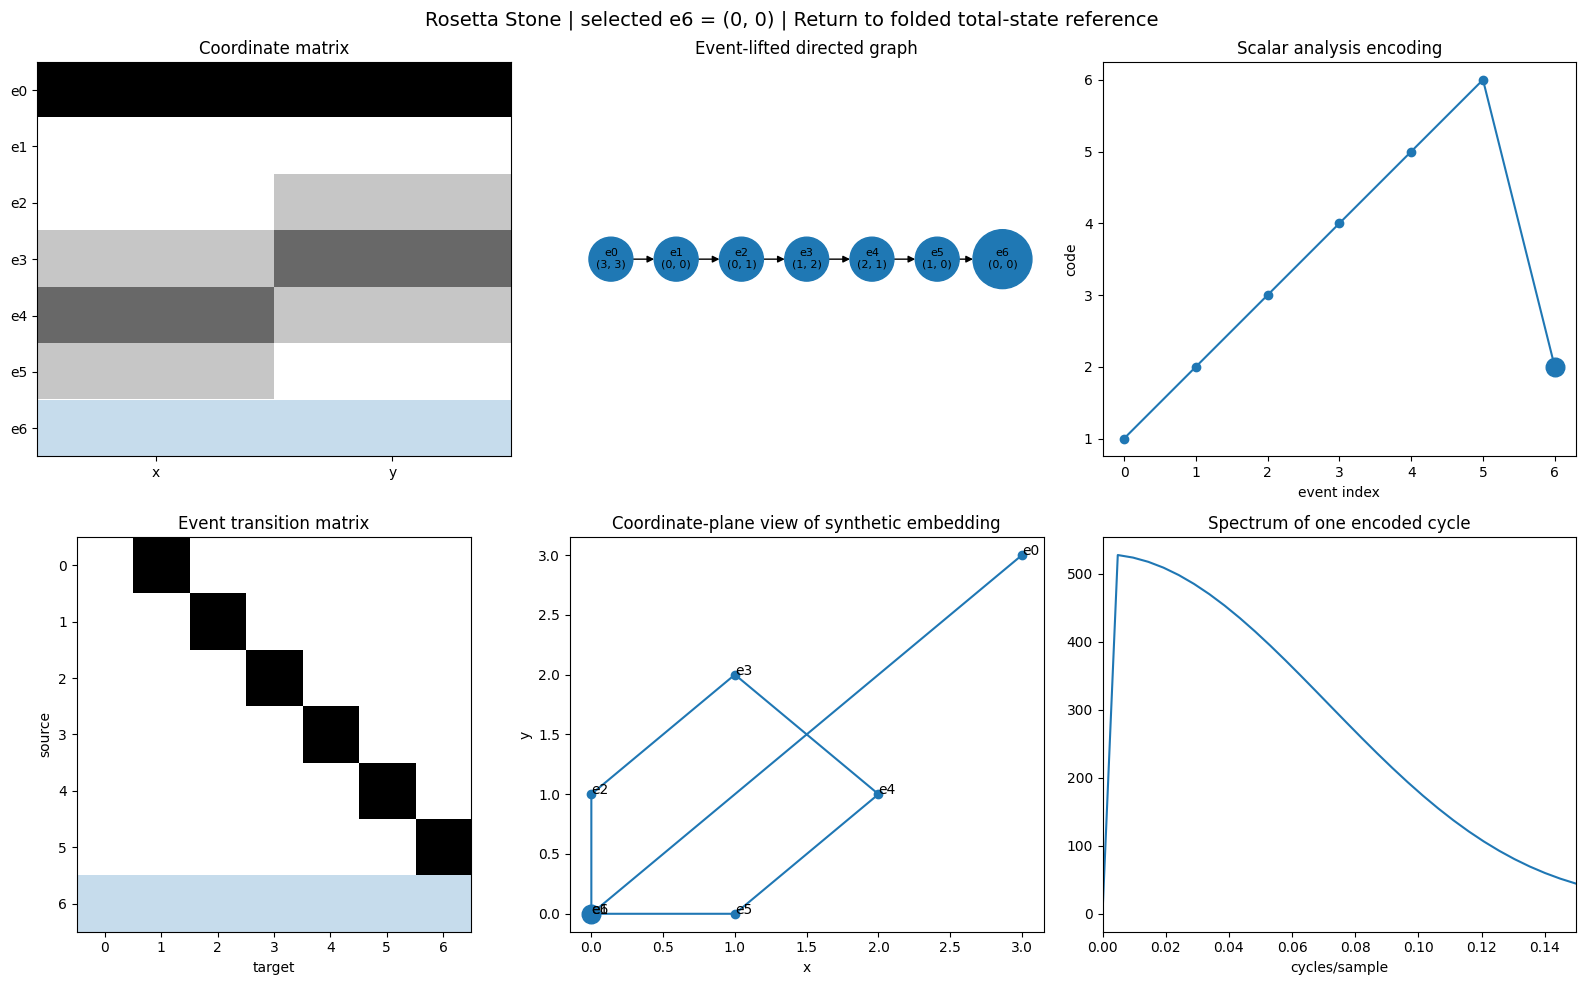

In [ ]:
def display_rosetta(step=0):
    step=int(step)
    if not 0<=step<len(P2_KERNEL):
        raise ValueError('step must be 0..6')

    fig,axes=plt.subplots(2,3,figsize=(16,10))

    # Matrix/event coordinate panel
    ax=axes[0,0]
    ax.imshow(P2_MATRIX,aspect='auto',cmap='Greys')
    ax.axhspan(step-0.5,step+0.5,alpha=0.25)
    ax.set_xticks([0,1],['x','y']); ax.set_yticks(range(7),EVENT_LABELS)
    ax.set_title('Coordinate matrix')

    # Event graph panel
    ax=axes[0,1]
    pos={i:(i,0) for i in range(7)}
    sizes=[1800 if i==step else 1000 for i in range(7)]
    nx.draw_networkx(EVENT_GRAPH,pos,ax=ax,node_size=sizes,labels={i:f'e{i}\n{P2_KERNEL[i]}' for i in range(7)},font_size=8,arrows=True)
    ax.set_title('Event-lifted directed graph'); ax.axis('off')

    # Encoded event series
    ax=axes[0,2]
    ax.plot(range(7),P2_CODES,'-o')
    ax.scatter([step],[P2_CODES[step]],s=180)
    ax.set_title('Scalar analysis encoding'); ax.set_xlabel('event index'); ax.set_ylabel('code')

    # Transition matrix
    ax=axes[1,0]
    A=nx.to_numpy_array(EVENT_GRAPH,nodelist=range(7),dtype=int)
    ax.imshow(A,cmap='Greys')
    ax.axhspan(step-0.5,step+0.5,alpha=0.25)
    ax.set_title('Event transition matrix'); ax.set_xlabel('target'); ax.set_ylabel('source')

    # Synthetic 3D embedding shown in 2D projection
    ax=axes[1,1]
    t=np.linspace(0,1,7)
    z=np.sin(np.pi*t)
    ax.plot(P2_MATRIX[:,0],P2_MATRIX[:,1],'-o')
    ax.scatter([P2_MATRIX[step,0]],[P2_MATRIX[step,1]],s=180)
    for i,(x,y) in enumerate(P2_MATRIX): ax.text(x,y,f'e{i}')
    ax.set_title('Coordinate-plane view of synthetic embedding'); ax.set_xlabel('x'); ax.set_ylabel('y')

    # Spectrum of one cycle
    ax=axes[1,2]
    sig=np.concatenate([P2_CODES,np.zeros(DELAY)])
    p=np.abs(np.fft.rfft(sig-sig.mean()))**2
    f=np.fft.rfftfreq(len(sig))
    ax.plot(f,p)
    ax.set_xlim(0,0.15); ax.set_title('Spectrum of one encoded cycle'); ax.set_xlabel('cycles/sample')

    fig.suptitle(f'Rosetta Stone | selected e{step} = {P2_KERNEL[step]} | {P2_ROLES[step]}',fontsize=14)
    plt.tight_layout(); plt.show()

for demo_step in [0,1,4,6]:
    display_rosetta(demo_step)

### 3. Mutation experiment

Swap two traversal positions while keeping the coordinate multiset fixed. The dashboard below reports which representation-derived diagnostics change.

In [ ]:
def edge_overlap(seq_a,seq_b):
    ea=list(zip(seq_a[:-1],seq_a[1:])); eb=list(zip(seq_b[:-1],seq_b[1:]))
    rem=list(ea); count=0
    for e in eb:
        if e in rem:
            count+=1; rem.remove(e)
    return count

def mutation_diagnostics(i=2,j=4):
    mutated=list(P2_KERNEL)
    mutated[i],mutated[j]=mutated[j],mutated[i]
    mutated=tuple(mutated)
    same_multiset=sorted(mutated)==sorted(P2_KERNEL)
    exact=mutated==P2_KERNEL
    positional=sum(a==b for a,b in zip(mutated,P2_KERNEL))
    edges=edge_overlap(P2_KERNEL,mutated)

    code_true=np.array([coord_codes[s] for s in P2_KERNEL],float)
    code_mut=np.array([coord_codes[s] for s in mutated],float)
    sig_true=np.concatenate([code_true,np.zeros(DELAY)])
    sig_mut=np.concatenate([code_mut,np.zeros(DELAY)])
    P=np.abs(np.fft.rfft(sig_true-sig_true.mean()))**2
    Q=np.abs(np.fft.rfft(sig_mut-sig_mut.mean()))**2
    spec=float(np.linalg.norm(P-Q)/max(np.linalg.norm(P),1e-12))
    return pd.DataFrame([{
        'swap':f'{i}<->{j}',
        'same_coordinate_multiset':same_multiset,
        'exact_order_preserved':exact,
        'positional_matches':positional,
        'canonical_edge_overlap':edges,
        'relative_spectral_difference':spec
    }])

display(mutation_diagnostics(2,4))
display(mutation_diagnostics(1,6))

,swap,same_coordinate_multiset,exact_order_preserved,positional_matches,canonical_edge_overlap,relative_spectral_difference
0,2<->4,True,False,5,2,0.091082


,swap,same_coordinate_multiset,exact_order_preserved,positional_matches,canonical_edge_overlap,relative_spectral_difference
0,1<->6,True,True,7,6,0.0


### 4. Cross-representation principle

The useful distinction is between the **underlying declared event sequence** and the mathematical representation used to inspect it. Some representation properties are preserved under a change of lens; others are intentionally lens-dependent. The purpose of this notebook is to make that separation visible rather than collapse the different mathematics into one another.

## End of combined Mathematical Foundations Lab

All seven mathematical lenses above operate on the same declared canonical structures while keeping analysis-specific encodings and representations explicitly separate from those structures.
